# 04 — EDA: UM-Dearborn ELB rooftop array (campus test site)
**Purpose:** decide whether the ELB array can serve as an unseen test site for the DKASC-trained system, *before* any cleaning.
Questions: (1) which columns are measurements, (2) coverage, (3) timestamps / time zone / label convention, (4) bad readings,
(5) snow, (6) array size and orientation, (7) calibration and test windows.
Input: `data/raw/ELB data/ELB Solar Hourly.xlsx` (hourly kWh), `ELB Electricity.xlsx` sheet *Solar* (daily, incl. a POA reference cell).

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pvlib
from pathlib import Path
RAW = Path('data/raw/ELB data'); FIG = Path('results/elb_eda'); FIG.mkdir(parents=True, exist_ok=True)
LAT, LON = 42.3175, -83.2300   # ELB roof, UM-Dearborn (approximate; timing is insensitive to ~1 km)
h = pd.read_excel(RAW/'ELB Solar Hourly.xlsx'); h.columns = ['ts', 'date', 'hour', 'meter', 'vendor']
h = h.set_index('ts')
s = pd.read_excel(RAW/'ELB Electricity.xlsx', sheet_name='Solar'); s.columns = ['day', 'kwh', 'poa', 'temp_a', 'temp_b', 'expected', 'estimate']
s = s.set_index('day')
INK, MUTED, S1, S2, S3 = '#1B2A3A', '#6B7280', '#2A78D6', '#EB6834', '#1BAF7A'
def style(ax):
    ax.spines[['top','right']].set_visible(False); ax.tick_params(labelsize=8, colors=MUTED); ax.grid(color='#E6E6E3', lw=0.6); ax.set_axisbelow(True)
print(h.index.min(), h.index.max(), len(h), '| meter non-null', h.meter.notna().sum())

2025-09-16 00:00:00 2026-07-16 23:00:00 7296 | meter non-null 5465


## 1. Which columns are measured? Meter vs vendor 'Site Performance' (daily)

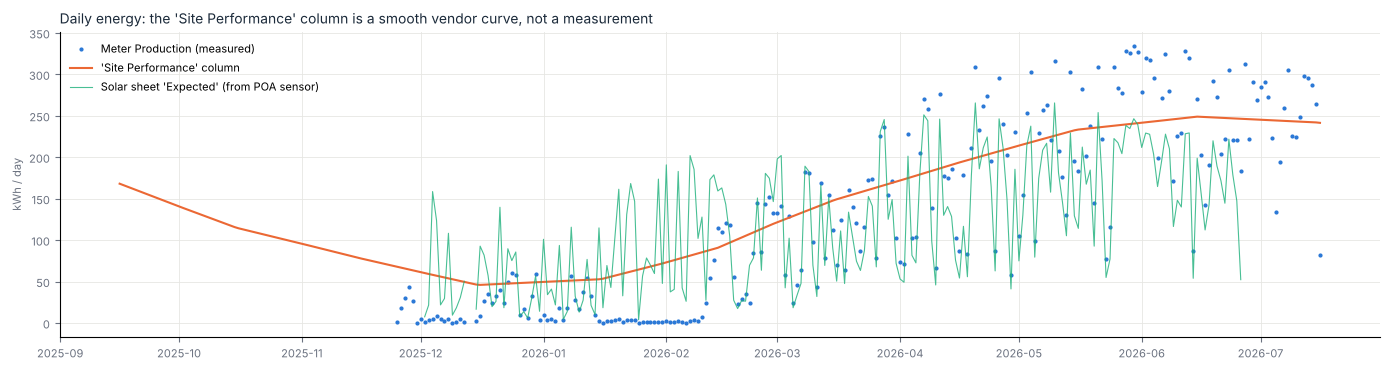

vendor day-to-day change is constant within a month: [-1.775 -1.778 -1.773 -1.776 -1.774]


In [2]:
d = h.groupby('date').agg(meter=('meter', lambda x: x.sum(min_count=1)), n=('meter', 'count'), vendor=('vendor', 'sum'))
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(d.index, d.meter, '.', ms=4, color=S1, label='Meter Production (measured)')
ax.plot(d.index, d.vendor, color=S2, lw=1.5, label="'Site Performance' column")
ax.plot(s.index, s.expected, color=S3, lw=0.8, alpha=0.8, label="Solar sheet 'Expected' (from POA sensor)")
ax.set_ylabel('kWh / day', fontsize=8, color=MUTED); style(ax); ax.legend(fontsize=8, frameon=False)
ax.set_title("Daily energy: the 'Site Performance' column is a smooth vendor curve, not a measurement", fontsize=10, color=INK, loc='left')
fig.tight_layout(); fig.savefig(FIG/'01_columns.png', dpi=150); plt.show()
print('vendor day-to-day change is constant within a month:', d.vendor.diff().loc['2025-10'].round(3).unique()[:5])

## 2. Coverage — hours with a meter reading per day

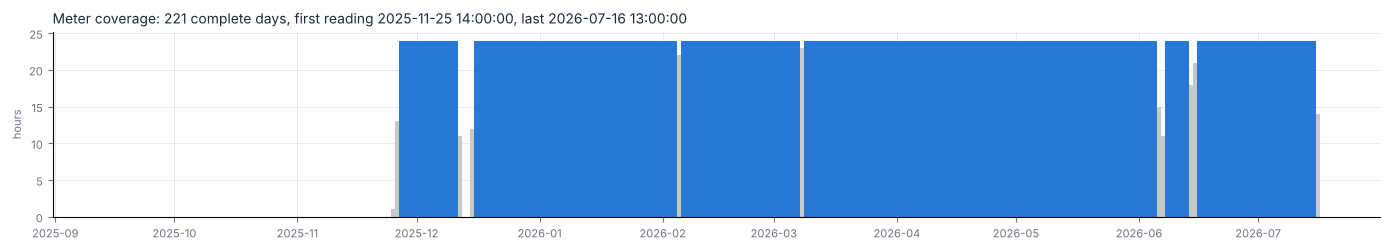

date
2025-09     0
2025-10     0
2025-11     4
2025-12    27
2026-01    31
2026-02    27
2026-03    30
2026-04    30
2026-05    31
2026-06    26
2026-07    15
Freq: M


In [3]:
fig, ax = plt.subplots(figsize=(14, 2.6))
ax.bar(d.index, d.n, width=1, color=np.where(d.n == 24, S1, '#C8C8C4'))
ax.set_ylabel('hours', fontsize=8, color=MUTED); style(ax)
ax.set_title(f"Meter coverage: {(d.n == 24).sum()} complete days, first reading {h.meter.first_valid_index()}, last {h.meter.last_valid_index()}", fontsize=10, color=INK, loc='left')
fig.tight_layout(); fig.savefig(FIG/'02_coverage.png', dpi=150); plt.show()
print((d.n == 24).groupby(d.index.to_period('M')).sum().to_string())

## 3. Timestamps — clock time, daylight saving, label convention
Energy-weighted centre of each day (hour label + 0.5 h, i.e. assuming labels mark the **start** of the hour) minus the centre of
modelled clear-sky GHI in **standard** time (UTC−5). Daylight-saving clock time would show a step of about +60 min on 8 Mar 2026.

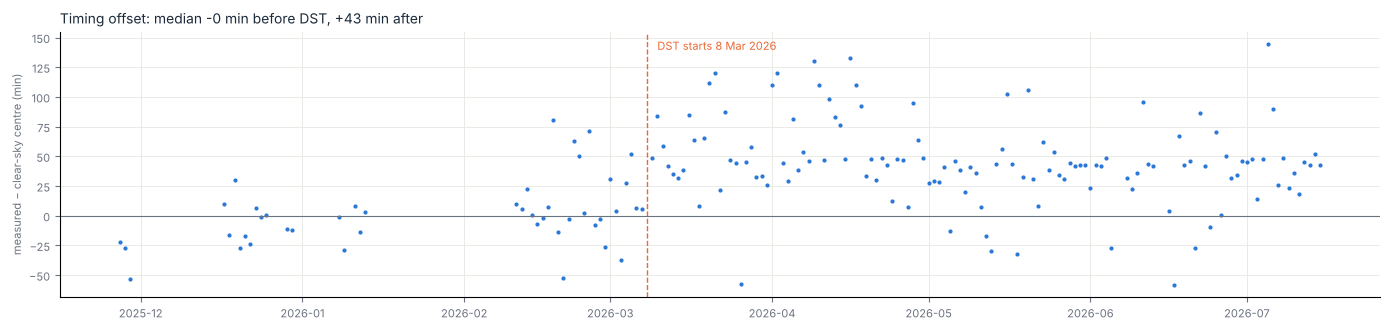

rows on 8 Mar 2026: 23 | hour-2 meter value that day: None


In [4]:
loc = pvlib.location.Location(LAT, LON, tz='Etc/GMT+5')
def cs_centre(day):
    t = pd.date_range(day, periods=288, freq='5min', tz='Etc/GMT+5'); g = loc.get_clearsky(t).ghi.to_numpy()
    return float(((t.hour + t.minute/60 + 2.5/60).to_numpy() * g).sum() / g.sum())
full = d[(d.n == 24) & (d.meter > 20)].index
rows = []
for day in full:
    x = h.meter[h.index.normalize() == day].clip(lower=0)
    rows.append((day, ((x.index.hour + 0.5) * x).sum() / x.sum() - cs_centre(day)))
off = pd.Series(dict(rows)) * 60
fig, ax = plt.subplots(figsize=(14, 3.4))
ax.plot(off.index, off, '.', ms=4, color=S1); ax.axvline(pd.Timestamp('2026-03-08'), color=S2, ls='--', lw=1)
ax.text(pd.Timestamp('2026-03-10'), off.max()-5, 'DST starts 8 Mar 2026', fontsize=8, color=S2)
ax.axhline(0, color=MUTED, lw=0.8); ax.set_ylabel('measured − clear-sky centre (min)', fontsize=8, color=MUTED); style(ax)
ax.set_title(f"Timing offset: median {off[:'2026-03-07'].median():+.0f} min before DST, {off['2026-03-08':].median():+.0f} min after", fontsize=10, color=INK, loc='left')
fig.tight_layout(); fig.savefig(FIG/'03_timestamps.png', dpi=150); plt.show()
print('rows on 8 Mar 2026:', (h.date == '2026-03-08').sum(), '| hour-2 meter value that day:', h.meter.get(pd.Timestamp('2026-03-08 02:00')))

## 4. Bad readings — hourly values above any plausible output

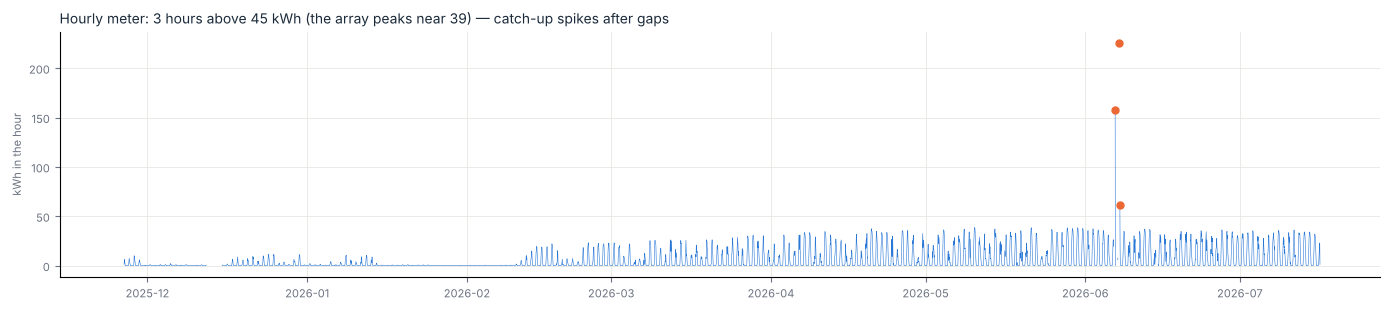

ts
2026-06-06 19:00:00    157.544
2026-06-07 15:00:00    225.637
2026-06-07 17:00:00     61.817
gap before each spike (hours with no reading):
2026-06-06 19:00:00 6
2026-06-07 15:00:00 21
2026-06-07 17:00:00 22
negative readings (night standby): 2740 min -0.051


In [5]:
fig, ax = plt.subplots(figsize=(14, 3.2))
ax.plot(h.index, h.meter, lw=0.4, color=S1)
bad = h.meter[h.meter > 45]
ax.plot(bad.index, bad, 'o', color=S2, ms=5); ax.set_ylabel('kWh in the hour', fontsize=8, color=MUTED); style(ax)
ax.set_title(f"Hourly meter: {len(bad)} hours above 45 kWh (the array peaks near 39) — catch-up spikes after gaps", fontsize=10, color=INK, loc='left')
fig.tight_layout(); fig.savefig(FIG/'04_outliers.png', dpi=150); plt.show()
print(bad.to_string()); print('gap before each spike (hours with no reading):')
for t in bad.index: print(t, int(h.meter.loc[t - pd.Timedelta(hours=48):t].isna().sum()))
print('negative readings (night standby):', (h.meter < 0).sum(), 'min', h.meter.min())

## 5. Snow — output relative to sunlight measured on the roof
Daily meter energy divided by daily plane-of-array insolation from the reference cell (Solar sheet). A covered array produces little
while the sensor still sees light.

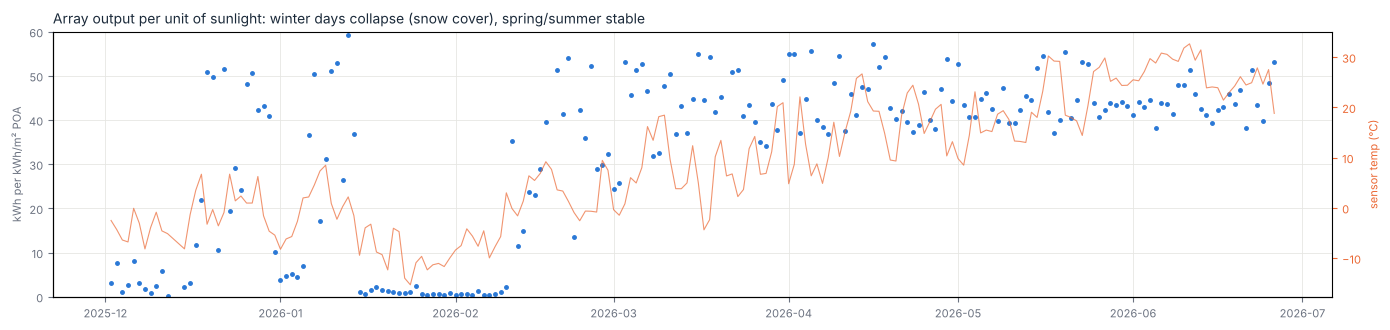

date
2025-12    10.4
2026-01     2.1
2026-02    23.4
2026-03    44.6
2026-04    44.5
2026-05    43.5
2026-06    43.7
Freq: M


In [6]:
j = d[['meter']].join(s[['poa', 'temp_a']], how='inner').dropna()
j['ratio'] = j.meter / (j.poa * 24 / 1000)   # kWh per kWh/m2 of plane-of-array sunlight
fig, ax = plt.subplots(figsize=(14, 3.4))
ax.plot(j.index, j.ratio, '.', ms=5, color=S1); ax.set_ylim(0, 60)
ax2 = ax.twinx(); ax2.plot(j.index, j.temp_a, color=S2, lw=0.8, alpha=0.7); ax2.set_ylabel('sensor temp (°C)', fontsize=8, color=S2); ax2.tick_params(labelsize=8, colors=S2)
ax.set_ylabel('kWh per kWh/m² POA', fontsize=8, color=MUTED); style(ax)
ax.set_title('Array output per unit of sunlight: winter days collapse (snow cover), spring/summer stable', fontsize=10, color=INK, loc='left')
fig.tight_layout(); fig.savefig(FIG/'05_snow.png', dpi=150); plt.show()
print(j.ratio.groupby(j.index.to_period('M')).median().round(1).to_string())

## 6. Array size and orientation — fitted from clear days
No nameplate yet. Grid-search tilt/azimuth by correlation of hourly measured energy with modelled clear-sky POA on the clearest days,
separately for the **calibration window** (before 1 Mar 2026) and the **test window**, to check the geometry is identified without test data.

calibration window best:
  corr  tilt  az  kw_per_kwm2
0.987     0 110       33.246
0.987     0 120       33.246
0.987     0 130       33.246
0.987     0 140       33.246
0.987     0 150       33.246
test window best:
  corr  tilt  az  kw_per_kwm2
0.996     5 110       42.841
0.996     5 120       42.687
0.996    10 140       42.067
0.996     5 130       42.549
0.996    10 150       41.884


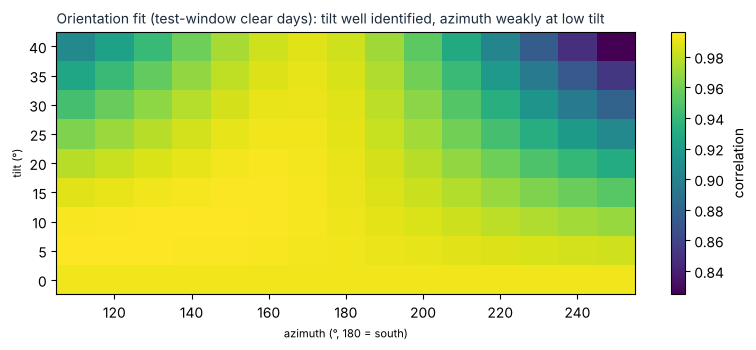

In [7]:
loc_dst = pvlib.location.Location(LAT, LON, tz='America/Detroit')
def poa_hourly(day, tilt, az):
    t = pd.date_range(day, periods=288, freq='5min', tz='America/Detroit')
    sp, cs = loc_dst.get_solarposition(t), loc_dst.get_clearsky(t)
    p = pvlib.irradiance.get_total_irradiance(tilt, az, sp.apparent_zenith, sp.azimuth, cs.dni, cs.ghi, cs.dhi).poa_global.fillna(0)
    return p.groupby(t.hour).mean().to_numpy()
csd = pd.Series({day: poa_hourly(day, 0, 180).sum() for day in full})
clear_ratio = d.meter.reindex(full) / (csd / 1000)
def fit(window):
    days = clear_ratio[window[0]:window[1]].nlargest(10).index
    y = np.concatenate([h.meter[h.date == day].clip(lower=0).to_numpy() for day in days])
    res = []
    for tilt in range(0, 41, 5):
        for az in range(110, 251, 10):
            x = np.concatenate([poa_hourly(day, tilt, az) for day in days])
            res.append((np.corrcoef(y, x)[0, 1], tilt, az, y.sum() / (x.sum() / 1000)))
    return pd.DataFrame(res, columns=['corr', 'tilt', 'az', 'kw_per_kwm2']).sort_values('corr', ascending=False)
cal, test = fit(('2025-11-25', '2026-02-28')), fit(('2026-03-01', '2026-07-16'))
print('calibration window best:\n', cal.head(5).round(3).to_string(index=False))
print('test window best:\n', test.head(5).round(3).to_string(index=False))
piv = test.pivot(index='tilt', columns='az', values='corr')
fig, ax = plt.subplots(figsize=(8, 3.6)); im = ax.imshow(piv, aspect='auto', origin='lower', cmap='viridis',
    extent=[piv.columns.min()-5, piv.columns.max()+5, piv.index.min()-2.5, piv.index.max()+2.5])
fig.colorbar(im, ax=ax, label='correlation'); ax.set_xlabel('azimuth (°, 180 = south)', fontsize=8); ax.set_ylabel('tilt (°)', fontsize=8)
ax.set_title('Orientation fit (test-window clear days): tilt well identified, azimuth weakly at low tilt', fontsize=10, color=INK, loc='left')
fig.tight_layout(); fig.savefig(FIG/'06_orientation.png', dpi=150); plt.show()

## 7. Decisions (applied in `src/data/build_dayahead.py`, site `elb`)
1. **Target = `Meter Production (kWh)` only.** `Site Performance` is a smooth vendor curve (constant daily step within each month), not a measurement.
2. **Timestamps:** labels mark the start of the hour in Detroit clock time with daylight saving (8 Mar 2026 has 23 rows; centre offset steps from ≈0 to ≈+43 min). Convert to standard time UTC−5, like every other site.
3. **Bad readings:** drop hours above 45 kWh (3 hours on 6–7 Jun, each right after a 6–22 h gap: meter catch-up). Night standby (≥ −0.05 kWh) → 0.
4. **Snow:** output per unit of roof sunlight collapses Dec–Feb and on clear days stays low into March. Winter is not used for testing (our physics has no snow model); this is reported as a limitation, not hidden.
5. **Geometry:** tilt/azimuth are only identifiable from test-window clear days (≈5–10°, azimuth weak), so they are **not** fitted: flat-roof prior 10°, south. Nameplate kWp / tilt / azimuth requested from Facilities.
6. **Windows:** calibration (one effective-capacity number, same method as Henderson/Golden) = 22 Mar – 21 Apr 2026; test = 22 Apr – 16 Jul 2026 (84 usable days). An earlier calibration window (1–21 Mar) under-estimates capacity by ~20% because of the low March output, see sensitivity note in the US Transfer Test vault note.
7. **Forecast issue time:** 19:00 EST on D−1 (GFS 18 UTC run is online ~17:30–18:30 EST).